In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris

# Configuración de paleta INF672
INDIGO, PURPLE, CORAL, INK, GREY = (
    "#4F46E5",
    "#7E22CE",
    "#F43F5E",
    "#111827",
    "#687280",
)
plt.rcParams.update({
    "axes.edgecolor": "#D1D5DB",
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "axes.grid": True,
    "grid.color": "#E5E7EB",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "figure.dpi": 110,
})

# Carga de datos
iris = load_iris()
df = pd.DataFrame(
    iris.data, columns=["sep_largo", "sep_ancho", "pet_largo", "pet_ancho"]
)
print("Forma del dataset:", df.shape)
df.head()

Forma del dataset: (150, 4)


,sep_largo,sep_ancho,pet_largo,pet_ancho
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [2]:
col = df["pet_largo"]
print("media  :", round(col.mean(), 3))
print("mediana:", round(col.median(), 3))
print("moda   :", col.mode().tolist())

media  : 3.758
mediana: 4.35
moda   : [1.4, 1.5]


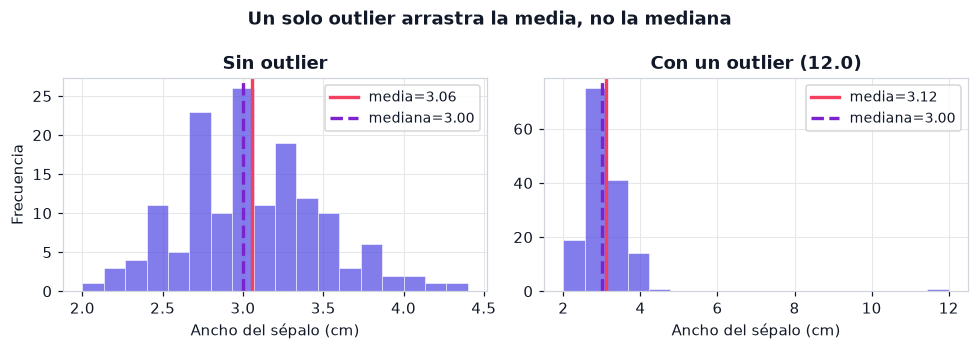

In [3]:
base = df["sep_ancho"].values
conout = np.append(base, 12.0)  # Ancho de sépalo atípico/imposible

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, data, titulo in [
    (axes[0], base, "Sin outlier"),
    (axes[1], conout, "Con un outlier (12.0)"),
]:
  ax.hist(
      data,
      bins=18,
      color=INDIGO,
      alpha=0.7,
      edgecolor="white",
      linewidth=0.5,
  )
  ax.axvline(
      data.mean(), color=CORAL, lw=2.2, label=f"media={data.mean():.2f}"
  )
  ax.axvline(
      np.median(data),
      color=PURPLE,
      lw=2.2,
      ls="--",
      label=f"mediana={np.median(data):.2f}",
  )
  ax.set_title(titulo)
  ax.set_xlabel("Ancho del sépalo (cm)")
  ax.legend(fontsize=9)

axes[0].set_ylabel("Frecuencia")
fig.suptitle(
    "Un solo outlier arrastra la media, no la mediana", fontweight="bold"
)
plt.tight_layout()
plt.show()

In [4]:
print("varianza:", round(col.var(ddof=0), 3))
print("desv. σ :", round(col.std(ddof=0), 3))

resumen = pd.DataFrame({
    "media": df.mean().round(2),
    "mediana": df.median().round(2),
    "desv_σ": df.std(ddof=0).round(2),
    "min": df.min().round(2),
    "max": df.max().round(2),
})
resumen

varianza: 3.096
desv. σ : 1.759


,media,mediana,desv_σ,min,max
sep_largo,5.84,5.80,0.83,4.3,7.9
sep_ancho,3.06,3.00,0.43,2.0,4.4
pet_largo,3.76,4.35,1.76,1.0,6.9
pet_ancho,1.20,1.30,0.76,0.1,2.5


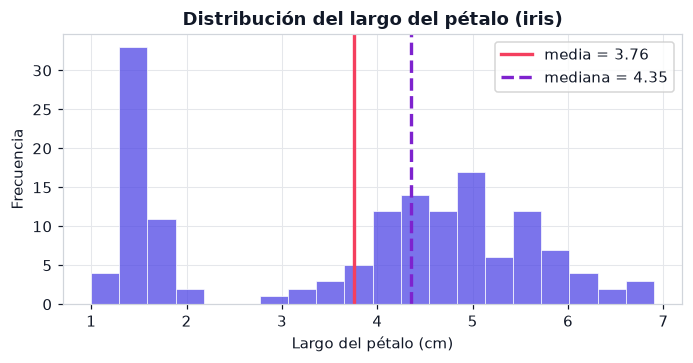

In [5]:
pl = df["pet_largo"].values
plt.figure(figsize=(6.4, 3.4))
plt.hist(
    pl, bins=20, color=INDIGO, alpha=0.75, edgecolor="white", linewidth=0.6
)
plt.axvline(pl.mean(), color=CORAL, lw=2.2, label=f"media = {pl.mean():.2f}")
plt.axvline(
    np.median(pl),
    color=PURPLE,
    lw=2.2,
    ls="--",
    label=f"mediana = {np.median(pl):.2f}",
)
plt.xlabel("Largo del pétalo (cm)")
plt.ylabel("Frecuencia")
plt.title("Distribución del largo del pétalo (iris)")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
df.corr().round(2)

,sep_largo,sep_ancho,pet_largo,pet_ancho
sep_largo,1.00,-0.12,0.87,0.82
sep_ancho,-0.12,1.00,-0.43,-0.37
pet_largo,0.87,-0.43,1.00,0.96
pet_ancho,0.82,-0.37,0.96,1.00


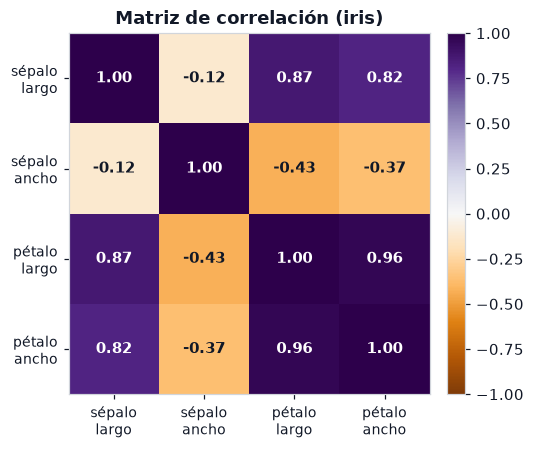

In [7]:
C = df.corr().values
labels = ["sépalo\nlargo", "sépalo\nancho", "pétalo\nlargo", "pétalo\nancho"]
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(C, cmap="PuOr", vmin=-1, vmax=1)
ax.set_xticks(range(4), labels, fontsize=9)
ax.set_yticks(range(4), labels, fontsize=9)

for i in range(4):
  for j in range(4):
    ax.text(
        j,
        i,
        f"{C[i, j]:.2f}",
        ha="center",
        va="center",
        color="white" if abs(C[i, j]) > 0.55 else INK,
        fontweight="bold",
    )

ax.set_title("Matriz de correlación (iris)")
ax.grid(False)
fig.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

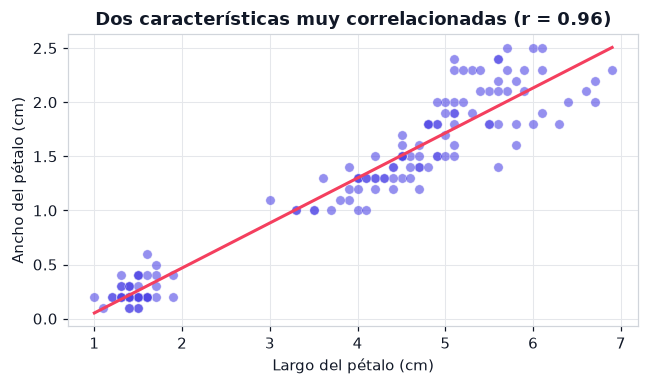

In [8]:
x, y = df["pet_largo"].values, df["pet_ancho"].values
r = np.corrcoef(x, y)[0, 1]
b1, b0 = np.polyfit(x, y, 1)

plt.figure(figsize=(6, 3.6))
plt.scatter(
    x, y, color=INDIGO, alpha=0.6, edgecolor="white", linewidth=0.4, s=38
)
plt.plot(
    [x.min(), x.max()], b0 + b1 * np.array([x.min(), x.max()]), color=CORAL, lw=2
)
plt.xlabel("Largo del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
plt.title(f"Dos características muy correlacionadas (r = {r:.2f})")
plt.tight_layout()
plt.show()

In [9]:
xc, yc = x - x.mean(), y - y.mean()
cos = xc @ yc / (np.linalg.norm(xc) * np.linalg.norm(yc))

print("Pearson (np.corrcoef):", round(np.corrcoef(x, y)[0, 1], 6))
print("coseno centrado     :", round(float(cos), 6))
print("¿idénticos? ->", np.isclose(np.corrcoef(x, y)[0, 1], cos))

Pearson (np.corrcoef): 0.962865
coseno centrado     : 0.962865
¿idénticos? -> True


In [10]:
# E1: Cálculo del IQR para sep_largo y pet_largo
q25_sep, q75_sep = np.percentile(df["sep_largo"], [25, 75])
iqr_sep = q75_sep - q25_sep

q25_pet, q75_pet = np.percentile(df["pet_largo"], [25, 75])
iqr_pet = q75_pet - q25_pet

print(
    f"IQR sep_largo: {round(iqr_sep, 2)} (Q1={q25_sep:.2f}, Q3={q75_sep:.2f})"
)
print(
    f"IQR pet_largo: {round(iqr_pet, 2)} (Q1={q25_pet:.2f}, Q3={q75_pet:.2f})"
)

IQR sep_largo: 1.3 (Q1=5.10, Q3=6.40)
IQR pet_largo: 3.5 (Q1=1.60, Q3=5.10)


Interpretación: El IQR de pet_largo (3.5 cm) es mucho mayor que el de sep_largo (1.3 cm). Esto confirma que el 50% central de los datos del pétalo tiene una dispersión significativamente más amplia debido a la separación entre las especies Iris-setosa y las demás.

In [11]:
# E2. Análisis por Clase/Especie
df["especie"] = iris.target
resumen_clase = df.groupby("especie")["pet_largo"].agg(
    media="mean", mediana="median", desv_std=lambda x: np.std(x, ddof=0)
)
especies_nom = {0: "setosa", 1: "versicolor", 2: "virginica"}
resumen_clase.index = resumen_clase.index.map(especies_nom)
resumen_clase.round(2)

,media,mediana,desv_std
especie,,,
setosa,1.46,1.50,0.17
versicolor,4.26,4.35,0.47
virginica,5.55,5.55,0.55


Interpretación: Al segmentar por especie, la bimodalidad desaparece. Cada especie individual presenta una desviación estándar muy baja en pet_largo (aproximadamente 0.17 a 0.55 cm), demostrando que la alta variabilidad global se debe a la diferencia entre especies y no a la varianza intra-clase.

In [12]:
# E3. Detección de Outliers mediante Regla 1.5 x IQR
Q1 = df["sep_ancho"].quantile(0.25)
Q3 = df["sep_ancho"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[
    (df["sep_ancho"] < limite_inferior) | (df["sep_ancho"] > limite_superior)
]
print(
    f"Límites: [{limite_inferior:.2f}, {limite_superior:.2f}] | Cantidad de"
    f" outliers: {len(outliers)}"
)
outliers[["sep_ancho"]]

Límites: [2.05, 4.05] | Cantidad de outliers: 4


,sep_ancho
15,4.4
32,4.1
33,4.2
60,2.0


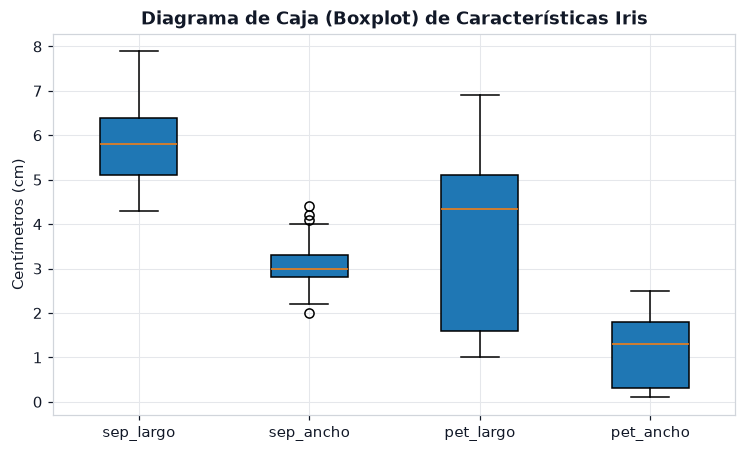

In [13]:
# E4. Gráfico Boxplot Comparativo 
plt.figure(figsize=(8, 4.5))
df_box = df.drop(columns=["especie"], errors="ignore")
plt.boxplot(df_box.values, tick_labels=df_box.columns, patch_artist=True)
plt.title("Diagrama de Caja (Boxplot) de Características Iris")
plt.ylabel("Centímetros (cm)")
plt.show()

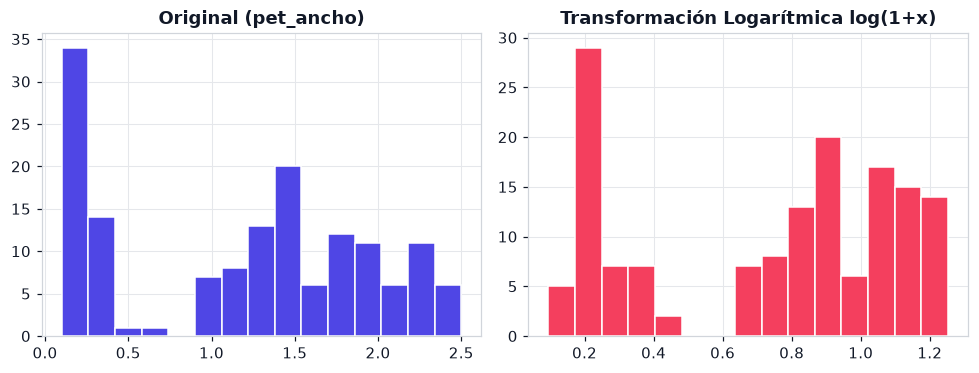

In [14]:
# E5. Transformación Logarítmica para Corregir Sesgo
pet_ancho_log = np.log1p(df["pet_ancho"])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].hist(df["pet_ancho"], bins=15, color=INDIGO, edgecolor="white")
axes[0].set_title("Original (pet_ancho)")

axes[1].hist(pet_ancho_log, bins=15, color=CORAL, edgecolor="white")
axes[1].set_title("Transformación Logarítmica log(1+x)")
plt.tight_layout()
plt.show()

E6: ¿Cuándo es preferible utilizar la mediana sobre la media en el preprocesamiento de un flujo de Machine Learning?
Es preferible utilizar la mediana en las siguientes situaciones principales:
    - Presencia de Outliers / Valores Atípicos: La mediana es una medida de tendencia central robusta. Como se demostró en el apartado 4.1, un solo  valor atípico distorsiona severamente la media, mientras que la mediana se mantiene estable.
    - Distribuciones Sesgadas o Multimodales: Cuando los datos no siguen una distribución normal simétrica (por ejemplo, distribuciones con colas largas o bimodales como pet_largo), la media puede caer en zonas con muy baja frecuencia de datos.
    - Imputación Seguro de Datos Faltantes: Rellenar datos faltantes (NaN) con la mediana evita introducir sesgos indeseados en el dataset cuando la variable contiene ruido o valores extremos.